In [16]:
import sys
path='/home/tomas/Ulmer-Berechnung/alps2qutipplus-april/alps2qutipplus-main/'

sys.path.insert(1, path) 

In [19]:
import numpy as np
import matplotlib.pyplot as plt
import qutip as qutip
import scipy.linalg as linalg

from alpsqutip import (build_system, list_models_in_alps_xml,
                       list_geometries_in_alps_xml, graph_from_alps_xml,
                       model_from_alps_xml,
                       restricted_maxent_toolkit as me)

from alpsqutip.operators.states.utils import safe_exp_and_normalize ## function used to safely and robustly map K-states to states
from alpsqutip.operators.states.meanfield import (one_body_from_qutip_operator, 
                                                  project_operator_to_m_body, 
                                                  project_to_n_body_operator,
                                                  project_qutip_operator_to_m_body,
                                                  project_meanfield,
                                                  self_consistent_project_meanfield,
                                                  self_consistent_quadratic_mfa)

from alpsqutip.operators import (
    ScalarOperator,
    LocalOperator,
    OneBodyOperator,
    Operator,
    ProductOperator,
    ScalarOperator,
    SumOperator,
)

from alpsqutip.scalarprod import gram_matrix
from alpsqutip.operators.states.gibbs import GibbsDensityOperator

In [20]:
params={}

params['size']=7
params['Jx']=1.; params['Jy'] = .75*params['Jx']; params['Jz']=1.05*params['Jx']

from scipy.optimize import root, fsolve
Ffactor=np.real(max(np.roots(np.poly1d([1, 0, -(params['Jx']*params['Jy']+params['Jx']*params['Jy']+params['Jy']*params['Jz']), 
                           -2*params['Jx']*params['Jy']*params['Jz']]))))
chi_y=fsolve(lambda x,y: x*np.arcsinh(x)-np.sqrt(x**2+1)-y, 1e-1, args=(0))[0]
vLR=4*Ffactor*chi_y

In [21]:
system=build_system(geometry_name= "open chain lattice",model_name="spin", 
                    L=params['size'], J=1)

sites=[s for s in system.sites]
sx_ops=[system.site_operator("Sx", '1[' + str(a) + ']') for a in range(len(system.sites))]
sy_ops=[system.site_operator("Sy", '1[' + str(a) + ']') for a in range(len(system.sites))]
sz_ops=[system.site_operator("Sz", '1[' + str(a) + ']') for a in range(len(system.sites))]

Sz = system.global_operator("Sz")
H = (
    params['Jx'] * sum(sx_ops[i] * sx_ops[i+1] for i in range(len(sites)-1)) +
    params['Jy'] * sum(sy_ops[i] * sy_ops[i+1] for i in range(len(sites)-1)) +
    params['Jz'] * sum(sz_ops[i] * sz_ops[i+1] for i in range(len(sites)-1))
)

idop = [system.site_operator('identity@1[' + str(a) + ']') for a in range(len(system.sites))]
idop = idop[0]*idop[1]*idop[2]#*idop[3]#*idop[4]*idop[5]*idop[6]

loading model spin  over graph open chain lattice


In [22]:
HBB0=[idop, 
      system.site_operator('Sx', '1[0]'), 
      system.site_operator('Sy', '1[0]'), 
      system.site_operator('Sz', '1[0]')]


phi0 = np.array([.0, .25, .25, 
                 -1.])

K0 = -me.k_state_from_phi_basis(phi0, HBB0)
sigma0 = GibbsDensityOperator(K0)
phi0[0] = np.log(sigma0.tr())
K0 = -me.k_state_from_phi_basis(phi0, HBB0)
sigma0 = GibbsDensityOperator(K0)

[(sigma0 * op).tr() for op in sz_ops] 

[0.22892976585114802,
 -1.734723475976807e-18,
 -1.734723475976807e-18,
 5.204170427930421e-18,
 1.734723475976807e-18,
 0.0,
 0.0]

In [23]:
obs_SzA=sum(sz for sz in sz_ops)

timespan=np.linspace(.0, 20.1/vLR,70)

In [24]:
## exact dynamics
exact_K_at_timet=qutip.mesolve(H=H.to_qutip(), rho0=K0.to_qutip(), tlist=timespan)
exact_rho_at_timet=[safe_exp_and_normalize(K_at_timeti)[0] for K_at_timeti in exact_K_at_timet.states]
evs_obs_ex=[qutip.expect(rho_at_timeti, obs_SzA.to_qutip()) for rho_at_timeti in exact_rho_at_timet]

### 1. Adapt-Max-Ent Ev

In [25]:
simulations={}

In [26]:
simulations[1] = {
    "parms":{
    "chosen_depth": 4,
    "m0": 3,
    "eps": 1e-3,
    },
  "saved_cut_times_index_ell":[0],
   "no_acts_ell" : [0],
    "local_bound_error_ell":[],
    "spectral_norm_Hij_tensor_ell":[],
    "instantaneous_w_errors":[],
} 

current_simulation = simulations[1]
current_simulation_parms = current_simulation["parms"]
chosen_depth = current_simulation_parms["chosen_depth"]
eps_tol = current_simulation_parms["eps"]
m0 = current_simulation_parms["m0"]

In [27]:
saved_cut_times_index_ell = current_simulation["saved_cut_times_index_ell"]  
no_acts_ell = current_simulation["no_acts_ell"]
current_simulation["number_of_commutators_ell"] = number_of_commutators_ell = [chosen_depth]

local_bound_error_ell = current_simulation["local_bound_error_ell"]
spectral_norm_Hij_tensor_ell=current_simulation["spectral_norm_Hij_tensor_ell"]
instantaneous_w_errors =  current_simulation["instantaneous_w_errors"]

phi0_proj_act_MF = []
# Start the computation

ev_obs_maxent_act_partialSum_ell = [(sigma0* obs_SzA).tr()]
current_simulation["ev_obs_maxent_act_partialSum_ell"] = ev_obs_maxent_act_partialSum_ell

sp_local = me.fetch_covar_scalar_product(sigma=sigma0); local_t_value = .0  

HBB_ell_act = me.build_hierarchical_basis(generator=H, seed_op=K0, deep=chosen_depth
                                         )  
orth_basis_act = me.orthogonalize_basis(basis=HBB_ell_act, sp=sp_local)  

# Compute the Hamiltonian tensor for the basis
Hij_tensor_act, w_errors = me.fn_hij_tensor_with_errors(generator=H, 
                                                        basis=orth_basis_act,
                                                        sp=sp_local)
instantaneous_w_errors.append(w_errors)

spectral_norm_Hij_tensor_ell.append(linalg.norm(Hij_tensor_act))

# Initial condition
phi0_proj_act = [sp_local(K0, op) for op in orth_basis_act]

# Initialize lists to store time-evolved values
phi_at_timet = [phi0_proj_act]  
K_at_timet = [K0]  
sigma_at_timet = [safe_exp_and_normalize(K0+1e-25*idop)]  
K_act_at_timet=[K0]

# Iterate through the time steps
for t in timespan[1:]:
    # Evolve the state phi(t) for a small time window
    phi_local = np.real(linalg.expm(Hij_tensor_act * (t - local_t_value)) @ phi0_proj_act)  
    K_local = me.k_state_from_phi_basis(phi=phi_local, basis=orth_basis_act)   
    sigma_local = GibbsDensityOperator(K_local) 
    
    phi_at_timet.append(phi_local)
    K_at_timet.append(K_local)
    
    ev_obs_maxent_act_partialSum_ell.append((sigma_local*obs_SzA).tr())  
    
    local_bound_error_ell.append(me.m_th_partial_sum(phi=phi_local, m=2) / me.m_th_partial_sum(phi=phi_local, m=0))  
    
    if abs(local_bound_error_ell[-1]) >= eps_tol:
        no_acts_ell.append(no_acts_ell[-1] + 1)    

        if list(timespan).index(t) % 50 == 0:  
            print("error", t)  
        
        local_t_value = t  
        saved_cut_times_index_ell.append(list(timespan).index(t))  

        K_act=project_operator_to_m_body(full_operator=K_local,
                                          sigma_0=sigma_local, m_max=1).to_qutip_operator()
        sigma_act=GibbsDensityOperator(K_act.to_qutip_operator())
        K_act_at_timet.append(K_act)
        print("hola", t)
        
        sp_local = me.fetch_covar_scalar_product(sigma=sigma_act)  
        HBB_ell_act = me.build_hierarchical_basis(generator=H,
                                                    seed_op=K_local, 
                                                    deep=chosen_depth)  

        HBB_ell_act=[project_operator_to_m_body(one_body_from_qutip_operator(op.to_qutip_operator()), m_max=m0,
                                               sigma_0=sigma_act) for op in HBB_ell_act]
          
        orth_basis_act = me.orthogonalize_basis(basis=HBB_ell_act, sp=sp_local)  
        
        instantaneous_w_errors.append(w_errors)
        spectral_norm_Hij_tensor_ell.append(linalg.norm(Hij_tensor_act))
        phi0_proj_act = np.array([sp_local(K_local, op) for op in orth_basis_act] )
        phi0_proj_act_MF.append(phi0_proj_act)
        new_K_local=me.k_state_from_phi_basis(phi=-phi0_proj_act, basis=orth_basis_act) + 1e-25*idop 
        print(linalg.norm((new_K_local - K_local).to_qutip()))
    else:
        # If error is below the threshold, retain the current basis and sp
        number_of_commutators_ell.append(number_of_commutators_ell[-1])  
        no_acts_ell.append(no_acts_ell[-1])  
        K_act_at_timet.append(K_local)

hola 0.7588118480930495
0.11167983086614491
hola 1.517623696186099
3.045115777275758e-10


### 2. Heisenberg Evolution

In [ ]:
def adaptive_Heisenberg_simulation(generator, rho0, tlist, simulation_params):
    local_bound_error=[]; saved_cut_times_index=[]; 
    no_acts=[0]; expectation_values=[]; 
    local_t_value=.0
    
    local_seed_op=simulation_params["obs"]; local_ell=simulation_params["depth"]; 
    local_tol=simulation_params["tol"]; local_nmax=simulation_params["nmax"]
    
    sp_local=me.fetch_covar_scalar_product(sigma=rho0)
    
    HBB_ell_act=me.build_hierarchical_basis(generator=H, 
                                            seed_op=K0, 
                                            deep=local_ell)
    
    orth_basis_act=me.orthogonalize_basis(basis=HBB_ell_act, sp=sp_local)
    
    Hij_tensor_act, w_errors = me.fn_hij_tensor_with_errors(generator=H, 
                                                            basis=orth_basis_act,
                                                            sp=sp_local)
    
    # Initial condition
    phi0_proj_act = [sp_local(local_seed_op, op) for op in orth_basis_act]
    
    phi_at_timet=[phi0_proj_act]; expectation_value=[(local_seed_op*rho0).tr()]
    
    for t in timespan[1:]:
        phi_local=np.real( linalg.expm(Hij_tensor_act * (t-local_t_value)) @ phi0_proj_act )
        local_seed_op = me.k_state_from_phi_basis(phi=phi_local,
                                                  basis=orth_basis_act)  
        
        expectation_values.append((local_seed_op*rho0).tr())
        
        local_bound_error.append(
            me.m_th_partial_sum(phi=phi_local, m=2)/me.m_th_partial_sum(phi=phi_local, m=0)
        )
        
        if abs(local_bound_error[-1]) >= local_tol:
            no_acts.append(no_acts[-1] + 1)
            if list(timespan).index(t)%30==0:
                print("Actualization at time t=", t)
            local_t_value=t; saved_cut_times_index.append(list(timespan).index(t))
            
            HBB_ell_act = me.build_hierarchical_basis(generator=H,
                                                        seed_op=local_seed_op, 
                                                        deep=chosen_depth)  

            HBB_ell_act=[project_operator_to_m_body(one_body_from_qutip_operator(op.to_qutip_operator()),
                                                    m_max=m0,
                                                    sigma_0=sigma_act) for op in HBB_ell_act]
          
            orth_basis_act = me.orthogonalize_basis(basis=HBB_ell_act, sp=sp_local)  
            
            phi0_proj_act = [sp_local(local_seed_op, op) for op in orth_basis_act]
        else:
            no_acts.append(no_acts[-1])
    
    return phi_at_timet, expectation_values

In [56]:
K_tgt=K_at_timet[51]

K_mf=one_body_from_qutip_operator(K_tgt.to_qutip_operator())
K_mf1=project_operator_to_m_body(K_mf, 
                                 sigma_0 = GibbsDensityOperator(K_tgt),
                                 m_max=1)

In [57]:
K_tgt.to_qutip_operator()

qutip interface operator for 1 x  
Quantum object: dims = [[2, 2, 2], [2, 2, 2]], shape = (8, 8), type = oper, isherm = True
Qobj data =
[[ 1.72179581e+00+0.j         -8.58667635e-03-0.02400236j
  -8.34700595e-02+0.03892253j -1.61055613e-03-0.01231115j
  -2.56420494e-02+0.14465525j  8.05278065e-03+0.j
  -3.14240208e-02-0.08189107j -6.14478932e-03+0.00544017j]
 [-8.58667635e-03+0.02400236j  1.74940534e+00+0.j
  -1.12738929e-02-0.08617802j -8.80142927e-02-0.03042426j
  -1.32399547e-01-0.03447121j -3.08776832e-02+0.13265528j
  -4.54293594e-02+0.04130231j  3.14240208e-02-0.08189107j]
 [-8.34700595e-02-0.03892253j -1.12738929e-02+0.08617802j
   1.98659490e+00+0.j         -7.64100308e-03+0.02891323j
   1.74872574e-01-0.40088146j  4.30135252e-02-0.0380812j
  -1.33906517e-01+0.01454529j -8.05278065e-03+0.j        ]
 [-1.61055613e-03+0.01231115j -8.80142927e-02+0.03042426j
  -7.64100308e-03-0.02891323j  2.01420444e+00+0.j
   8.56062351e-03-0.00221906j -1.74872574e-01-0.40088146j
   1.32399547e-

In [58]:
K_mf1.to_qutip_operator()

qutip interface operator for 1 x  
Quantum object: dims = [[2, 2, 2], [2, 2, 2]], shape = (8, 8), type = oper, isherm = True
Qobj data =
[[ 1.72169738+0.j         -0.00409191+0.00672126j -0.03391803+0.04292181j
   0.        +0.j         -0.08363239+0.07547951j  0.        +0.j
   0.        +0.j          0.        +0.j        ]
 [-0.00409191-0.00672126j  1.74922986+0.j          0.        +0.j
  -0.03391803+0.04292181j  0.        +0.j         -0.08363239+0.07547951j
   0.        +0.j          0.        +0.j        ]
 [-0.03391803-0.04292181j  0.        +0.j          1.98663328+0.j
  -0.00409191+0.00672126j  0.        +0.j          0.        +0.j
  -0.08363239+0.07547951j  0.        +0.j        ]
 [ 0.        +0.j         -0.03391803-0.04292181j -0.00409191-0.00672126j
   2.01416576+0.j          0.        +0.j          0.        +0.j
   0.        +0.j         -0.08363239+0.07547951j]
 [-0.08363239-0.07547951j  0.        +0.j          0.        +0.j
   0.        +0.j          2.41369585+0.j

In [45]:
sp_local(K_mf1-K_tgt,K_mf1-K_tgt)

2.7977620220553945e-13

In [53]:

K_mf2=project_operator_to_m_body(K_mf1.to_qutip_operator(), 
                                 sigma_0 = safe_exp_and_normalize(K_mf1.to_qutip_operator())[0],
                                 m_max=1)

In [56]:
K_mf1.to_qutip_operator()

qutip interface operator for 1 x  
Quantum object: dims = [[2, 2, 2], [2, 2, 2]], shape = (8, 8), type = oper, isherm = True
Qobj data =
[[-0.4920297 +0.j         -0.00352753+0.00681958j -0.03460501+0.04282194j
   0.        +0.j         -0.08454105+0.07527226j  0.        +0.j
   0.        +0.j          0.        +0.j        ]
 [-0.00352753-0.00681958j -0.46426419+0.j          0.        +0.j
  -0.03460501+0.04282194j  0.        +0.j         -0.08454105+0.07527226j
   0.        +0.j          0.        +0.j        ]
 [-0.03460501-0.04282194j  0.        +0.j         -0.22738456+0.j
  -0.00352753+0.00681958j  0.        +0.j          0.        +0.j
  -0.08454105+0.07527226j  0.        +0.j        ]
 [ 0.        +0.j         -0.03460501-0.04282194j -0.00352753-0.00681958j
  -0.19961904+0.j          0.        +0.j          0.        +0.j
   0.        +0.j         -0.08454105+0.07527226j]
 [-0.08454105-0.07527226j  0.        +0.j          0.        +0.j
   0.        +0.j          0.19961806+0.j

In [57]:
K_mf2.to_qutip_operator()

qutip interface operator for 1 x  
Quantum object: dims = [[2, 2, 2], [2, 2, 2]], shape = (8, 8), type = oper, isherm = True
Qobj data =
[[-0.4920297 +0.j         -0.00352753+0.00681958j -0.03460501+0.04282194j
   0.        +0.j         -0.08454105+0.07527226j  0.        +0.j
   0.        +0.j          0.        +0.j        ]
 [-0.00352753-0.00681958j -0.46426419+0.j          0.        +0.j
  -0.03460501+0.04282194j  0.        +0.j         -0.08454105+0.07527226j
   0.        +0.j          0.        +0.j        ]
 [-0.03460501-0.04282194j  0.        +0.j         -0.22738456+0.j
  -0.00352753+0.00681958j  0.        +0.j          0.        +0.j
  -0.08454105+0.07527226j  0.        +0.j        ]
 [ 0.        +0.j         -0.03460501-0.04282194j -0.00352753-0.00681958j
  -0.19961904+0.j          0.        +0.j          0.        +0.j
   0.        +0.j         -0.08454105+0.07527226j]
 [-0.08454105-0.07527226j  0.        +0.j          0.        +0.j
   0.        +0.j          0.19961806+0.j

In [58]:
K_mf1

  (Local Operator on site 1[0]:
 array([[-0.34582383+0.j        , -0.08454105+0.07527226j],
       [-0.08454105-0.07527226j,  0.34582393+0.j        ]]))
  +(Local Operator on site 1[1]:
 array([[-0.13232266+0.j        , -0.03460501+0.04282194j],
       [-0.03460501-0.04282194j,  0.13232248+0.j        ]]))
  +(Local Operator on site 1[2]:
 array([[-0.0138832 +0.j        , -0.00352753+0.00681958j],
       [-0.00352753-0.00681958j,  0.01388231+0.j        ]]))

In [59]:
K_mf2

  (Local Operator on site 1[2]:
 array([[-0.01413442+0.j        , -0.00352753+0.00681958j],
       [-0.00352753-0.00681958j,  0.0136311 +0.j        ]]))
  +(Local Operator on site 1[1]:
 array([[-0.15272357+0.j        , -0.03460501+0.04282194j],
       [-0.03460501-0.04282194j,  0.11192158+0.j        ]]))
  +(Local Operator on site 1[0]:
 array([[-0.32517171+0.j        , -0.08454105+0.07527226j],
       [-0.08454105-0.07527226j,  0.36647605+0.j        ]]))

In [48]:
sp_local(K_act-Ktgt, K_act-Ktgt)

(152.04828628598622+9.707525488818658e-13j)

In [41]:
Ktgt.to_qutip()

Quantum object: dims = [[2, 2, 2], [2, 2, 2]], shape = (8, 8), type = oper, isherm = True
Qobj data =
[[-4.84245726e+01+0.00000000e+00j -2.56619852e-02-3.24648310e-02j
  -8.11045370e-02+7.33231695e-02j -4.04180778e-01-2.31988216e+00j
  -6.22003356e-03+1.31954854e-01j  2.02090389e+00-1.27194712e+00j
  -5.24135395e+00-9.87333899e+00j -8.80896412e-03+7.04067321e-03j]
 [-2.56619852e-02+3.24648310e-02j -4.14957592e+01+0.00000000e+00j
  -2.82926545e+00-1.62391751e+01j -1.03445399e-01-2.99721717e-02j
  -1.81138712e+01-8.24732294e+00j -1.86594460e-02+9.90066627e-02j
  -6.77254605e-02+5.73683280e-02j  5.24135395e+00-9.87333899e+00j]
 [-8.11045370e-02-7.33231695e-02j -2.82926545e+00+1.62391751e+01j
  -1.21968301e+01+0.00000000e+00j -1.28727702e-02+4.98053519e-02j
   2.53724159e+01-3.78221733e+01j  6.16627488e-02-4.92847125e-02j
  -1.00204850e-01-2.23032684e-03j -2.02090389e+00-1.27194712e+00j]
 [-4.04180778e-01+2.31988216e+00j -1.03445399e-01+2.99721717e-02j
  -1.28727702e-02-4.98053519e-02j -5.

In [40]:
K_act.to_qutip()

Quantum object: dims = [[2, 2, 2], [2, 2, 2]], shape = (8, 8), type = oper, isherm = False
Qobj data =
[[-4.84246384e+01+0.00000000e+00j -6.57130716e-02+3.88333080e-03j
  -5.70703621e-02+3.74854039e-02j  3.91196197e-01-2.31986217e+00j
  -4.40874947e-05+8.95963568e-02j -1.92873899e+00-1.27181243e+00j
   2.96248796e+00-9.87352869e+00j  0.00000000e+00+0.00000000e+00j]
 [-6.57130716e-02-3.88333080e-03j -4.14960407e+01+0.00000000e+00j
   2.73838128e+00-1.62391655e+01j -1.03348150e-01-3.40975815e-02j
   1.72880532e+01-8.24727814e+00j  1.31050715e-02-5.33058040e-03j
   0.00000000e+00+0.00000000e+00j  2.96248796e+00-9.87352869e+00j]
 [-5.70703621e-02-3.74854039e-02j  2.73838128e+00+1.62391655e+01j
  -1.21966829e+01+0.00000000e+00j -5.11720514e-03+4.26906791e-02j
  -1.43412849e+01-3.78222411e+01j  0.00000000e+00+0.00000000e+00j
  -1.34127476e-01+6.16800961e-02j -1.92873899e+00-1.27181243e+00j]
 [ 3.91196197e-01+2.31986217e+00j -1.03348150e-01+3.40975815e-02j
  -5.11720514e-03-4.26906791e-02j -5

In [42]:
sp_local(K_act-Ktgt, K_act-Ktgt)

(6.716905474265205+8.770497256035026e-13j)

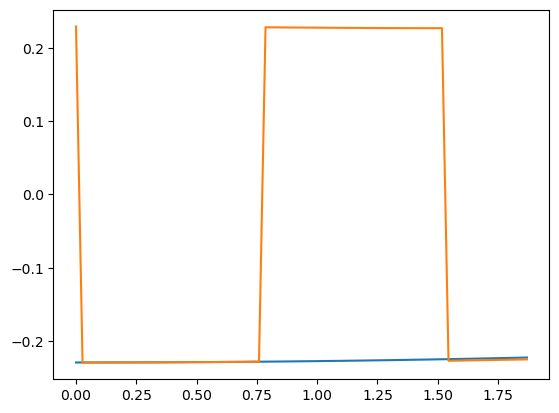

In [28]:
plt.plot(timespan, evs_obs_ex)
plt.plot(timespan, ev_obs_maxent_act_partialSum_ell)

In [45]:
(safe_exp_and_normalize(K_local)[0] * sigma0).tr()

(0.12663089693566085-4.552802091491864e-21j)

In [49]:
(safe_exp_and_normalize(K_proj)[0] * sigma0).tr()

(0.22578719439645817+3.494010907423989e-21j)

In [48]:
type(K_proj)

alpsqutip.operators.arithmetic.SumOperator

In [58]:
K_local=K_at_timet[45]
K_proj=project_operator_to_m_body(K_local, sigma_0=sigma0, m_max=2)

In [59]:
K_local.to_qutip()

Quantum object: dims = [[2, 2, 2], [2, 2, 2]], shape = (8, 8), type = oper, isherm = True
Qobj data =
[[-4.93924599e+01+0.00000000e+00j -4.14959023e-03-1.98623619e-02j
  -8.02893928e-02+2.58365128e-02j -1.01348651e-01-8.96077352e-01j
  -3.45255804e-02+1.49095382e-01j  5.06743253e-01+0.00000000e+00j
  -2.45031988e+00-7.34378042e+00j -5.04897028e-03+4.60556993e-03j]
 [-4.14959023e-03+1.98623619e-02j -4.76550544e+01+0.00000000e+00j
  -7.09440555e-01-6.27254146e+00j -7.96239416e-02-2.99354933e-02j
  -1.10337602e+01-2.50901659e+00j -3.86698002e-02+1.40694519e-01j
  -3.68630217e-02+3.42659625e-02j  2.45031988e+00-7.34378042e+00j]
 [-8.02893928e-02-2.58365128e-02j -7.09440555e-01+6.27254146e+00j
  -2.73249394e+01+0.00000000e+00j -6.91167498e-03+2.21031070e-02j
   1.43144769e+01-3.88613800e+01j  3.53427920e-02-3.22389895e-02j
  -1.42708857e-01+2.56785138e-02j -5.06743253e-01+0.00000000e+00j]
 [-1.01348651e-01+8.96077352e-01j -7.96239416e-02+2.99354933e-02j
  -6.91167498e-03-2.21031070e-02j -2.

In [60]:
K_proj.to_qutip()

Quantum object: dims = [[2, 2, 2], [2, 2, 2]], shape = (8, 8), type = oper, isherm = True
Qobj data =
[[-4.93924546e+01+0.00000000e+00j -1.88430648e-02-6.43573749e-03j
  -6.81094554e-02+1.07789899e-02j  1.01348651e-01-8.96071810e-01j
  -3.34614195e-02+1.48031221e-01j  0.00000000e+00+0.00000000e+00j
   0.00000000e+00-7.34378042e+00j  0.00000000e+00+0.00000000e+00j]
 [-1.88430648e-02+6.43573749e-03j -4.76550598e+01+0.00000000e+00j
   7.09440555e-01-6.27253434e+00j -9.18038789e-02-1.48779704e-02j
   0.00000000e+00-2.50901659e+00j -3.97339610e-02+1.41758679e-01j
   0.00000000e+00+0.00000000e+00j  0.00000000e+00-7.34378042e+00j]
 [-6.81094554e-02-1.07789899e-02j  7.09440555e-01+6.27253434e+00j
  -2.73249447e+01+0.00000000e+00j  7.78179960e-03+8.67648269e-03j
   0.00000000e+00-3.88613800e+01j  0.00000000e+00+0.00000000e+00j
  -1.43773018e-01+2.67426746e-02j  0.00000000e+00+0.00000000e+00j]
 [ 1.01348651e-01+8.96071810e-01j -9.18038789e-02+1.48779704e-02j
   7.78179960e-03-8.67648269e-03j -2.

In [61]:
linalg.norm((K_local - K_proj).to_qutip())

36.548072500902485

In [29]:
sp_local(K_at_timet[45]-K_at_timet[44], K_at_timet[45]-K_at_timet[44])

0.07774658851065219

In [30]:
sp_local(K_local-K_at_timet[44], K_local-K_at_timet[44])

0.07774658851065219

In [22]:
project_operator_to_m_body(K_local, sigma_0=sigma0, m_max=3).to_qutip()

Quantum object: dims = [[2, 2, 2], [2, 2, 2]], shape = (8, 8), type = oper, isherm = True
Qobj data =
[[-4.93924599e+01+0.00000000e+00j -4.14959023e-03-1.98623619e-02j
  -8.02893928e-02+2.58365128e-02j -1.01348651e-01-8.96077352e-01j
  -3.45255804e-02+1.49095382e-01j  5.06743253e-01+0.00000000e+00j
  -2.45031988e+00-7.34378042e+00j -5.04897028e-03+4.60556993e-03j]
 [-4.14959023e-03+1.98623619e-02j -4.76550544e+01+0.00000000e+00j
  -7.09440555e-01-6.27254146e+00j -7.96239416e-02-2.99354933e-02j
  -1.10337602e+01-2.50901659e+00j -3.86698002e-02+1.40694519e-01j
  -3.68630217e-02+3.42659625e-02j  2.45031988e+00-7.34378042e+00j]
 [-8.02893928e-02-2.58365128e-02j -7.09440555e-01+6.27254146e+00j
  -2.73249394e+01+0.00000000e+00j -6.91167498e-03+2.21031070e-02j
   1.43144769e+01-3.88613800e+01j  3.53427920e-02-3.22389895e-02j
  -1.42708857e-01+2.56785138e-02j -5.06743253e-01+0.00000000e+00j]
 [-1.01348651e-01+8.96077352e-01j -7.96239416e-02+2.99354933e-02j
  -6.91167498e-03-2.21031070e-02j -2.

In [26]:
K_at_timet[44].to_qutip()

Quantum object: dims = [[2, 2, 2], [2, 2, 2]], shape = (8, 8), type = oper, isherm = True
Qobj data =
[[-4.94200337e+01+0.00000000e+00j -3.52169405e-03-1.91402628e-02j
  -7.94933000e-02+2.37369999e-02j -9.30971463e-02-8.44073312e-01j
  -3.61512450e-02+1.49703571e-01j  4.65485731e-01+0.00000000e+00j
  -2.34276116e+00-7.19564245e+00j -4.86774572e-03+4.46044571e-03j]
 [-3.52169405e-03+1.91402628e-02j -4.78240827e+01+0.00000000e+00j
  -6.51680024e-01-5.90851318e+00j -7.81189286e-02-2.97949857e-02j
  -1.06607902e+01-2.36340527e+00j -4.01047181e-02+1.41840018e-01j
  -3.54706773e-02+3.30850629e-02j  2.34276116e+00-7.19564245e+00j]
 [-7.94933000e-02-2.37369999e-02j -6.51680024e-01+5.90851318e+00j
  -2.80984533e+01+0.00000000e+00j -6.78565929e-03+2.10519099e-02j
   1.37926080e+01-3.85524708e+01j  3.40742201e-02-3.12231200e-02j
  -1.43945104e-01+2.76597339e-02j -4.65485731e-01+0.00000000e+00j]
 [-9.30971463e-02+8.44073312e-01j -7.81189286e-02+2.97949857e-02j
  -6.78565929e-03-2.10519099e-02j -2.

In [28]:
terms=[op for op in K_local.terms]
proj_terms=[project_operator_to_m_body(op, sigma_0=sigma0, m_max=2) for op in K_local.terms]
proj_terms_sum=sum(proj_terms)

In [48]:
[op for op in (K0+1e-10*idop).terms]

[  1e-10 * (
   ([[1.+0.j 0.+0.j]
  [0.+0.j 1.+0.j]] <-  1[0])  (x)
   ([[1.+0.j 0.+0.j]
  [0.+0.j 1.+0.j]] <-  1[1])  (x)
   ([[1.+0.j 0.+0.j]
  [0.+0.j 1.+0.j]] <-  1[2])
    ),
 Local Operator on site 1[0]:
  array([[-50.   +0.j   ,  -0.125+0.125j],
        [ -0.125-0.125j,  50.   +0.j   ]])]

In [40]:
aa

10

In [29]:
proj_terms_sum

(
qutip interface operator for 1 x  
Quantum object: dims = [[2, 2], [2, 2]], shape = (4, 4), type = oper, isherm = True
Qobj data =
[[0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]]
  +qutip interface operator for 1 x  
Quantum object: dims = [[2, 2], [2, 2]], shape = (4, 4), type = oper, isherm = True
Qobj data =
[[0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]]
  +qutip interface operator for 0.6010442667830391 x  
Quantum object: dims = [[2, 2], [2, 2]], shape = (4, 4), type = oper, isherm = True
Qobj data =
[[  0.78125   +0.j          -0.04921875+0.065625j
    0.05203125-0.06570313j   0.        +0.j        ]
 [ -0.04921875-0.065625j    38.28125   +0.j
    0.        +0.j           0.05203125-0.06570313j]
 [  0.05203125+0.06570313j   0.        +0.j
  -38.28125   +0.j          -0.04921875+0.065625j  ]
 [  0.        +0.j           0.05203125+0.06570313j
   -0.04921875-0.065625j    -0.78125   +0.j        ]]
  +Local Operator on site 1[0]:
 array([[-11.739176  +0.j

In [23]:
K_local

(
qutip interface operator for 0.6010442667830391 x  
Quantum object: dims = [[2, 2], [2, 2]], shape = (4, 4), type = oper, isherm = True
Qobj data =
[[  0.78125   +0.j          -0.04921875+0.065625j
    0.05203125-0.06570313j   0.        +0.j        ]
 [ -0.04921875-0.065625j    38.28125   +0.j
    0.        +0.j           0.05203125-0.06570313j]
 [  0.05203125+0.06570313j   0.        +0.j
  -38.28125   +0.j          -0.04921875+0.065625j  ]
 [  0.        +0.j           0.05203125+0.06570313j
   -0.04921875-0.065625j    -0.78125   +0.j        ]]
  +qutip interface operator for 0.6010442667830391 x  
Quantum object: dims = [[2, 2, 2], [2, 2, 2]], shape = (8, 8), type = oper, isherm = True
Qobj data =
[[ 0.0000000e+00+0.j          2.3437500e-02-0.0234375j
  -2.4609375e-02+0.0328125j   0.0000000e+00+0.j
   0.0000000e+00+0.j          0.0000000e+00+0.j
  -3.2812500e+00+0.j         -8.2031250e-03+0.00820312j]
 [ 2.3437500e-02+0.0234375j   0.0000000e+00+0.j
   0.0000000e+00+0.j          2.46

In [19]:
k1,s1=self_consistent_project_meanfield(K0, idop)

     S(curr||target)=-51.386606860143324
     S(curr||target)=-51.38660686014332
     S(curr||target)=-51.38660686014332
     S(curr||target)=-51.38660686014332
     S(curr||target)=-51.38660686014332
     S(curr||target)=-51.38660686014332
     S(curr||target)=-51.38660686014332
     S(curr||target)=-51.38660686014332
     S(curr||target)=-51.38660686014332
     S(curr||target)=-51.38660686014332
     S(curr||target)=-51.38660686014332
     S(curr||target)=-51.38660686014332
     S(curr||target)=-51.38660686014332
     S(curr||target)=-51.38660686014332
     S(curr||target)=-51.38660686014332
     S(curr||target)=-51.38660686014332
     S(curr||target)=-51.38660686014332
     S(curr||target)=-51.38660686014332
     S(curr||target)=-51.38660686014332
     S(curr||target)=-51.38660686014332
     S(curr||target)=-51.38660686014332
     S(curr||target)=-51.38660686014332


In [23]:
-k1

  ((-1.3862943611198906-0j) * Identity )
  +(Local Operator on site 1[0]:
 array([[-3.12499023e-04+0.j   ,  1.25000000e-01-0.125j],
       [ 1.25000000e-01+0.125j, -1.00000312e+02+0.j   ]]))

In [22]:
sigma0

qutip interface operator for 1 x  
Quantum object: dims = [[2, 2, 2], [2, 2, 2]], shape = (8, 8), type = oper, isherm = True
Qobj data =
[[ 7.81242676e-07+0.j         0.00000000e+00+0.j
   0.00000000e+00+0.j         0.00000000e+00+0.j
  -3.12498047e-04+0.0003125j  0.00000000e+00+0.j
   0.00000000e+00+0.j         0.00000000e+00+0.j       ]
 [ 0.00000000e+00+0.j         7.81242676e-07+0.j
   0.00000000e+00+0.j         0.00000000e+00+0.j
   0.00000000e+00+0.j        -3.12498047e-04+0.0003125j
   0.00000000e+00+0.j         0.00000000e+00+0.j       ]
 [ 0.00000000e+00+0.j         0.00000000e+00+0.j
   7.81242676e-07+0.j         0.00000000e+00+0.j
   0.00000000e+00+0.j         0.00000000e+00+0.j
  -3.12498047e-04+0.0003125j  0.00000000e+00+0.j       ]
 [ 0.00000000e+00+0.j         0.00000000e+00+0.j
   0.00000000e+00+0.j         7.81242676e-07+0.j
   0.00000000e+00+0.j         0.00000000e+00+0.j
   0.00000000e+00+0.j        -3.12498047e-04+0.0003125j]
 [-3.12498047e-04-0.0003125j  0.00000000

In [47]:
project_operator_to_m_body(H.terms[0], sigma_0=sigma0, m_max=1)

Local Operator on site 1[1]:
 array([[ 0.      +0.j, -0.000625+0.j],
       [-0.000625+0.j,  0.      +0.j]])

In [51]:
.5**3 * qutip.sigmax()*qutip.expect(sx_ops[0].to_qutip(), sigma0.to_qutip())

Quantum object: dims = [[2], [2]], shape = (2, 2), type = oper, isherm = True
Qobj data =
[[ 0.         -0.00015625]
 [-0.00015625  0.        ]]

In [43]:
H.terms[0]

{'1[0]': Quantum object: dims = [[2], [2]], shape = (2, 2), type = oper, isherm = True
 Qobj data =
 [[0.  0.5]
  [0.5 0. ]],
 '1[1]': Quantum object: dims = [[2], [2]], shape = (2, 2), type = oper, isherm = True
 Qobj data =
 [[0.  0.5]
  [0.5 0. ]]}

In [34]:
K_act_at_timet[45]

(
(1e-25+0j) * Identity 
  +  (Local Operator on site 1[0]:
 array([[-35.1130157 +0.j        ,  -0.09387042+0.09479623j],
       [ -0.09387042-0.09479623j,  39.86692107+0.j        ]]))
  +(Local Operator on site 1[1]:
 array([[-13.38768553+0.j        ,  -0.03579145+0.03636802j],
       [ -0.03579145-0.03636802j,   8.67979856+0.j        ]]))
  +(Local Operator on site 1[2]:
 array([[-1.01267069+0.j        , -0.00195448+0.00472311j],
       [-0.00195448-0.00472311j,  0.96040227+0.j        ]]))
)

In [169]:
K_act=project_operator_to_m_body(full_operator=K_at_timet[45],
                                          sigma_0=sigma_local, m_max=1)

In [193]:
K_act=project_operator_to_m_body(K_at_timet[45], sigma_0=sigma0, m_max=3)

In [189]:
linalg.norm(K_at_timet[45].to_qutip()-K_act.to_qutip())

88.1823213934771

In [192]:
linalg.norm(K_at_timet[45].to_qutip()-K_act.to_qutip())

36.548072500902485

In [194]:
linalg.norm(K_at_timet[45].to_qutip()-K_act.to_qutip())

0.0

In [161]:
sigma0.logm()

qutip interface operator for 1 x  
Quantum object: dims = [[2, 2, 2], [2, 2, 2]], shape = (8, 8), type = oper, isherm = True
Qobj data =
[[-3.74298351e+01+0.j          0.00000000e+00+0.j
   0.00000000e+00+0.j          0.00000000e+00+0.j
  -4.50542851e-02+0.04505429j  0.00000000e+00+0.j
   0.00000000e+00+0.j          0.00000000e+00+0.j        ]
 [ 0.00000000e+00+0.j         -6.90773413e+01+0.j
   0.00000000e+00+0.j          0.00000000e+00+0.j
   0.00000000e+00+0.j         -8.46135442e-02+0.08461354j
   0.00000000e+00+0.j          0.00000000e+00+0.j        ]
 [ 0.00000000e+00+0.j          0.00000000e+00+0.j
  -3.74298351e+01+0.j          0.00000000e+00+0.j
   0.00000000e+00+0.j          0.00000000e+00+0.j
  -4.50542851e-02+0.04505429j  0.00000000e+00+0.j        ]
 [ 0.00000000e+00+0.j          0.00000000e+00+0.j
   0.00000000e+00+0.j         -3.74298351e+01+0.j
   0.00000000e+00+0.j          0.00000000e+00+0.j
   0.00000000e+00+0.j         -4.50542851e-02+0.04505429j]
 [-4.50542851e-02-0

In [138]:
sigma0

qutip interface operator for 1 x  
Quantum object: dims = [[2, 2, 2], [2, 2, 2]], shape = (8, 8), type = oper, isherm = True
Qobj data =
[[ 7.81242676e-07+0.j         0.00000000e+00+0.j
   0.00000000e+00+0.j         0.00000000e+00+0.j
  -3.12498047e-04+0.0003125j  0.00000000e+00+0.j
   0.00000000e+00+0.j         0.00000000e+00+0.j       ]
 [ 0.00000000e+00+0.j         7.81242676e-07+0.j
   0.00000000e+00+0.j         0.00000000e+00+0.j
   0.00000000e+00+0.j        -3.12498047e-04+0.0003125j
   0.00000000e+00+0.j         0.00000000e+00+0.j       ]
 [ 0.00000000e+00+0.j         0.00000000e+00+0.j
   7.81242676e-07+0.j         0.00000000e+00+0.j
   0.00000000e+00+0.j         0.00000000e+00+0.j
  -3.12498047e-04+0.0003125j  0.00000000e+00+0.j       ]
 [ 0.00000000e+00+0.j         0.00000000e+00+0.j
   0.00000000e+00+0.j         7.81242676e-07+0.j
   0.00000000e+00+0.j         0.00000000e+00+0.j
   0.00000000e+00+0.j        -3.12498047e-04+0.0003125j]
 [-3.12498047e-04-0.0003125j  0.00000000

In [140]:
.5*(sigma_act_at_timet[0]+sigma_act_at_timet[0].dag())

qutip interface operator for 0.5 x  
Quantum object: dims = [[2, 2, 2], [2, 2, 2]], shape = (8, 8), type = oper, isherm = True
Qobj data =
[[ 1.49847799e-06+0.00000000e+00j  2.10023324e-08-2.18428336e-08j
  -4.30098059e-06-3.08455262e-06j -6.91655443e-11-2.91526673e-08j
  -3.08004818e-04+3.16883380e-04j  3.45858550e-10+0.00000000e+00j
  -3.01231919e-06-4.23436086e-04j -7.53003713e-09+7.52977561e-09j]
 [ 2.10023324e-08+2.18428336e-08j  1.49966310e-06+0.00000000e+00j
  -4.83958411e-10-2.04068686e-07j -4.25665953e-06-3.14543296e-06j
  -1.72112279e-05-8.16279508e-08j -3.08005021e-04+3.16883175e-04j
  -5.27113249e-08+5.27098509e-08j  3.01231920e-06-4.23436086e-04j]
 [-4.30098059e-06+3.08455262e-06j -4.83958411e-10+2.04068686e-07j
   3.59209339e-05+0.00000000e+00j -2.12096568e-08+2.16445709e-08j
   2.10842987e-05-2.96364447e-03j  5.27102993e-08-5.27084792e-08j
  -3.16895546e-04+3.07992293e-04j -3.45860101e-10+0.00000000e+00j]
 [-6.91655443e-11+2.91526673e-08j -4.25665953e-06+3.14543296e-06j


In [135]:
linalg.norm((sigma_at_timet[3].to_qutip()-sigma_act_at_timet[3].to_qutip()))

0.005988190636500662

In [123]:
sigma_act_at_timet[0].to_qutip()-sigma_at_timet[0].to_qutip()

Quantum object: dims = [[2, 2, 2], [2, 2, 2]], shape = (8, 8), type = oper, isherm = True
Qobj data =
[[ 7.17235317e-07+0.00000000e+00j  2.10023324e-08-2.18428336e-08j
  -4.30098059e-06-3.08455262e-06j -6.91655443e-11-2.91526673e-08j
   4.49322892e-06+4.38533355e-06j  3.45858550e-10+0.00000000e+00j
  -3.01231919e-06-4.23436086e-04j -7.53003713e-09+7.52977561e-09j]
 [ 2.10023324e-08+2.18428336e-08j  7.18420427e-07+0.00000000e+00j
  -4.83958411e-10-2.04068686e-07j -4.25665953e-06-3.14543296e-06j
  -1.72112279e-05-8.16279508e-08j  4.49302630e-06+4.38512803e-06j
  -5.27113249e-08+5.27098509e-08j  3.01231920e-06-4.23436086e-04j]
 [-4.30098059e-06+3.08455262e-06j -4.83958411e-10+2.04068686e-07j
   3.51396912e-05+0.00000000e+00j -2.12096568e-08+2.16445709e-08j
   2.10842987e-05-2.96364447e-03j  5.27102993e-08-5.27084792e-08j
  -4.39749895e-06-4.50575435e-06j -3.45860101e-10+0.00000000e+00j]
 [-6.91655443e-11+2.91526673e-08j -4.25665953e-06+3.14543296e-06j
  -2.12096568e-08-2.16445709e-08j  3.

In [124]:
(sigma_act_at_timet[0]-sigma_at_timet[0]).to_qutip()

Quantum object: dims = [[2, 2, 2], [2, 2, 2]], shape = (8, 8), type = oper, isherm = True
Qobj data =
[[-7.81242676e-07+0.j         0.00000000e+00+0.j
   0.00000000e+00+0.j         0.00000000e+00+0.j
   3.12498047e-04-0.0003125j  0.00000000e+00+0.j
   0.00000000e+00+0.j         0.00000000e+00+0.j       ]
 [ 0.00000000e+00+0.j        -7.81242676e-07+0.j
   0.00000000e+00+0.j         0.00000000e+00+0.j
   0.00000000e+00+0.j         3.12498047e-04-0.0003125j
   0.00000000e+00+0.j         0.00000000e+00+0.j       ]
 [ 0.00000000e+00+0.j         0.00000000e+00+0.j
  -7.81242676e-07+0.j         0.00000000e+00+0.j
   0.00000000e+00+0.j         0.00000000e+00+0.j
   3.12498047e-04-0.0003125j  0.00000000e+00+0.j       ]
 [ 0.00000000e+00+0.j         0.00000000e+00+0.j
   0.00000000e+00+0.j        -7.81242676e-07+0.j
   0.00000000e+00+0.j         0.00000000e+00+0.j
   0.00000000e+00+0.j         3.12498047e-04-0.0003125j]
 [ 3.12498047e-04+0.0003125j  0.00000000e+00+0.j
   0.00000000e+00+0.j     

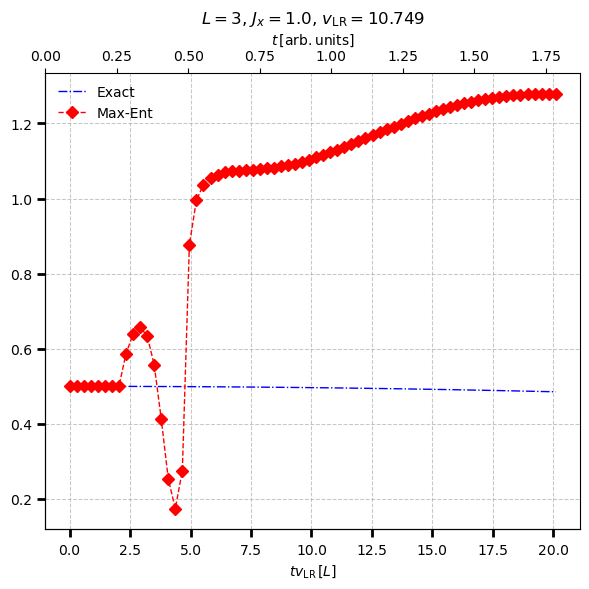

In [88]:
# Création de la figure et des axes
fig, ax = plt.subplots(figsize=(6, 6))

n=1
ax.plot(timespan * vLR, evs_obs_ex, label='Exact', color="blue", linestyle='dashdot', linewidth=1)
ax.plot(timespan[::n] * vLR, ev_obs_maxent_act_partialSum_ell[::n], label='Max-Ent', 
        color='red', linestyle='--', marker='D', linewidth=1)

# Bordures uniquement à gauche et en bas (style minimaliste)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# Personnalisation des ticks
ax.tick_params(direction='out', length=6, width=2, which='major', grid_alpha=0.6)
ax.grid(True, which='major', linestyle='--', linewidth=0.75, alpha=0.7)

ax.legend(frameon=False, loc='upper left')

# Create a secondary x-axis (twinned) and set its limits
ax1 = ax.twiny()
ax1.set_xlim(timespan[0], timespan[-1])

# Set axis labels
ax.set_xlabel(r'$t v_{\rm LR} \, [L]$')
ax1.set_xlabel(r'$t \, [{\rm arb. units}]$')

# Format the title using the `params` dictionary values
# Ensure proper LaTeX formatting and consistent escape sequences
plt.title(r'$L={}$, $J_x={}$, $v_{{\rm LR}}={}$'.format(
    params['size'], 
    round(params['Jx'], 3), 
    round(vLR, 3)
))

# Adjustment final et affichage
plt.tight_layout()